# Lab 13: Convolutional Neural Network on MNIST

MLPR, Semester 4. A small CNN (three convolutional layers, two max-pooling layers, then two dense layers) built with TensorFlow/Keras, trained for 5 epochs on the MNIST handwritten digits.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets, layers, models

tf.keras.utils.set_random_seed(0)
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()
train_images = train_images.reshape((60000, 28, 28, 1)).astype("float32") / 255
test_images = test_images.reshape((10000, 28, 28, 1)).astype("float32") / 255

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

In [2]:
history = model.fit(train_images, train_labels, epochs=5, batch_size=64,
                    validation_data=(test_images, test_labels), verbose=2)
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
print(f"\nTest accuracy: {test_acc:.4f}, test loss: {test_loss:.4f}")

Epoch 1/5


938/938 - 17s - 18ms/step - accuracy: 0.9436 - loss: 0.1869 - val_accuracy: 0.9797 - val_loss: 0.0621


Epoch 2/5


938/938 - 20s - 22ms/step - accuracy: 0.9842 - loss: 0.0505 - val_accuracy: 0.9873 - val_loss: 0.0406


Epoch 3/5


938/938 - 18s - 19ms/step - accuracy: 0.9896 - loss: 0.0343 - val_accuracy: 0.9867 - val_loss: 0.0381


Epoch 4/5


938/938 - 19s - 20ms/step - accuracy: 0.9919 - loss: 0.0262 - val_accuracy: 0.9882 - val_loss: 0.0380


Epoch 5/5


938/938 - 22s - 24ms/step - accuracy: 0.9933 - loss: 0.0219 - val_accuracy: 0.9906 - val_loss: 0.0292



Test accuracy: 0.9906, test loss: 0.0292


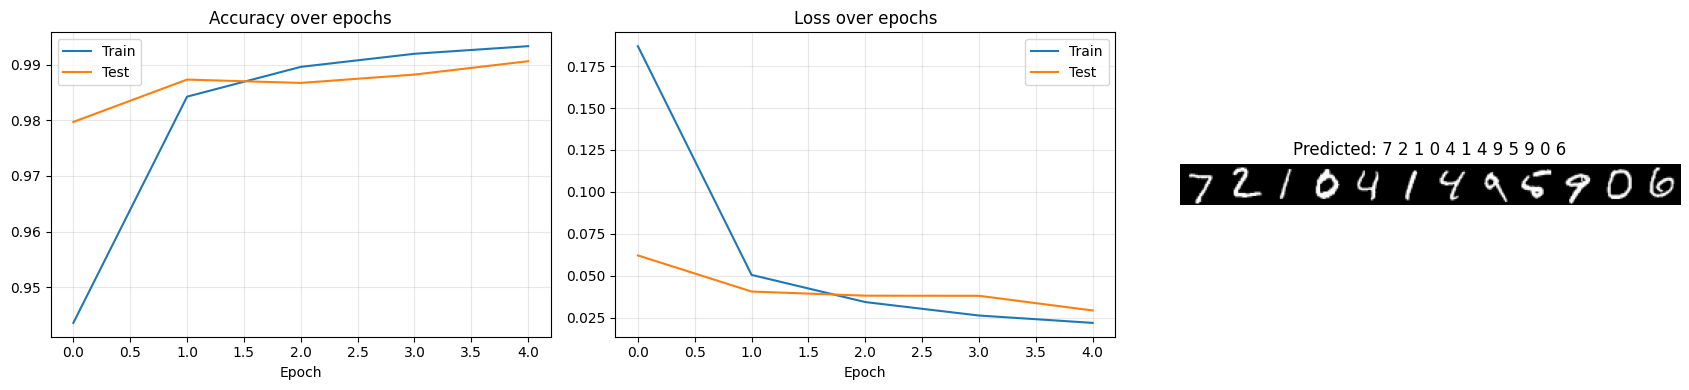

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(history.history["accuracy"], label="Train"); axes[0].plot(history.history["val_accuracy"], label="Test")
axes[0].set_title("Accuracy over epochs"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history.history["loss"], label="Train"); axes[1].plot(history.history["val_loss"], label="Test")
axes[1].set_title("Loss over epochs"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
pred = model.predict(test_images[:12], verbose=0).argmax(axis=1)
axes[2].imshow(np.hstack([test_images[i, :, :, 0] for i in range(12)]), cmap="gray")
axes[2].set_title("Predicted: " + " ".join(map(str, pred))); axes[2].axis("off")
plt.tight_layout()
plt.savefig("images/lab13_mnist.png")
plt.show()

## Report

**a) Layers for feature extraction and classification.** Feature extraction: 3 convolutional layers and 2 max-pooling layers. Classification: a flatten layer and 2 dense layers.

**b) Kernels in the first convolutional layer.** 32 kernels (filters), each 3 x 3.

**c) Pooling.** Max pooling with a 2 x 2 window. It halves the height and width of each feature map, which reduces computation and keeps the strongest response in each region, giving some tolerance to small shifts.

**d) Feature dimensions per layer.** Input 28 x 28 x 1 -> conv 26 x 26 x 32 -> pool 13 x 13 x 32 -> conv 11 x 11 x 64 -> pool 5 x 5 x 64 -> conv 3 x 3 x 64 -> flatten 576 -> dense 64 -> dense 10 (see `model.summary()` above). Each 3 x 3 convolution without padding trims 2 pixels, and each pooling halves the size. The network gradually trades spatial detail for more abstract features.

**e) From outputs to class probabilities.** The last dense layer uses a softmax activation, which turns the 10 raw scores into probabilities that sum to 1. The digit with the highest probability is the prediction.